# CA3

### Imports

In [48]:
# for preprocessing
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# different classifers
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier 


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# for measuring performance
from sklearn.metrics import accuracy_score


# for feature selection
from sklearn.feature_selection import SequentialFeatureSelector

# To stop warnings from
import warnings
warnings.filterwarnings("ignore", category=Warning, module="sklearn")

### Reading data

In [ ]:
train = pd.read_csv("train.csv")
train.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.8,0.610,0.29,1.6,0.114,9.0,29.0,0.99740,3.26,1.56,9.1,0,13
1,8.4,1.035,0.15,6.0,0.073,11.0,54.0,0.99900,3.37,0.49,9.9,0,705
2,8.1,0.290,0.36,2.2,0.048,35.0,53.0,0.99500,3.27,1.01,12.4,1,1408
3,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,1,144
4,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,0,557


### Data exploration and visualisation

#### Overview of the training data
The output below shows the number of rows and columns, missing values, how balanced the two quality classes are (`quality`: 0 = lower quality, 1 = higher quality), and summary statistics (mean, std, min, quartiles, max) for every column. `Id` is only a row identifier and carries no information about wine quality.

In [50]:
# Size of the data, summary statistics and class balance
print("Train shape (rows, columns):", train.shape)
print("How much of each quality"+"\n", train["quality"].value_counts(normalize=True), "\n")
train.describe().T # Transposed table

Train shape (rows, columns): (835, 13)
How much of each quality
 quality
1    0.500599
0    0.499401
Name: proportion, dtype: float64 



,count,mean,std,min,25%,50%,75%,max
fixed acidity,835.0,8.310898,1.757359,4.60000,7.1000,7.90000,9.1000,15.90000
volatile acidity,835.0,0.540042,0.179786,0.12000,0.4100,0.54000,0.6475,1.58000
citric acid,835.0,0.260790,0.197739,0.00000,0.0800,0.24000,0.4100,1.00000
residual sugar,835.0,2.542994,1.420451,0.90000,1.9000,2.20000,2.6000,15.50000
chlorides,835.0,0.088674,0.051485,0.01200,0.0710,0.08000,0.0910,0.61100
free sulfur dioxide,835.0,15.859880,10.444733,1.00000,7.0000,13.00000,21.0000,68.00000
total sulfur dioxide,835.0,47.077246,33.271056,7.00000,22.0000,38.00000,63.0000,289.00000
density,835.0,0.996799,0.001946,0.99007,0.9956,0.99675,0.9979,1.00369
pH,835.0,3.308707,0.159072,2.74000,3.2000,3.31000,3.4000,4.01000
sulphates,835.0,0.658048,0.179891,0.33000,0.5500,0.61000,0.7250,2.00000


#### Pairplot
Compares all 13 characteristics to every other characteristic making a 13x13 grid of small plots.
Each small plot compared a feature named at the bottom of its column (x-axis) with a feature named to the left of the row (y-axis).
Points are colors by quality where orange means 1, blue means 0.

on the diagonal, features are compared to itself, so seabord shows a distribution graph for each quality.
Above and below the diagonal, the plots are mirrored since they each feature compare to each other in oposite order.


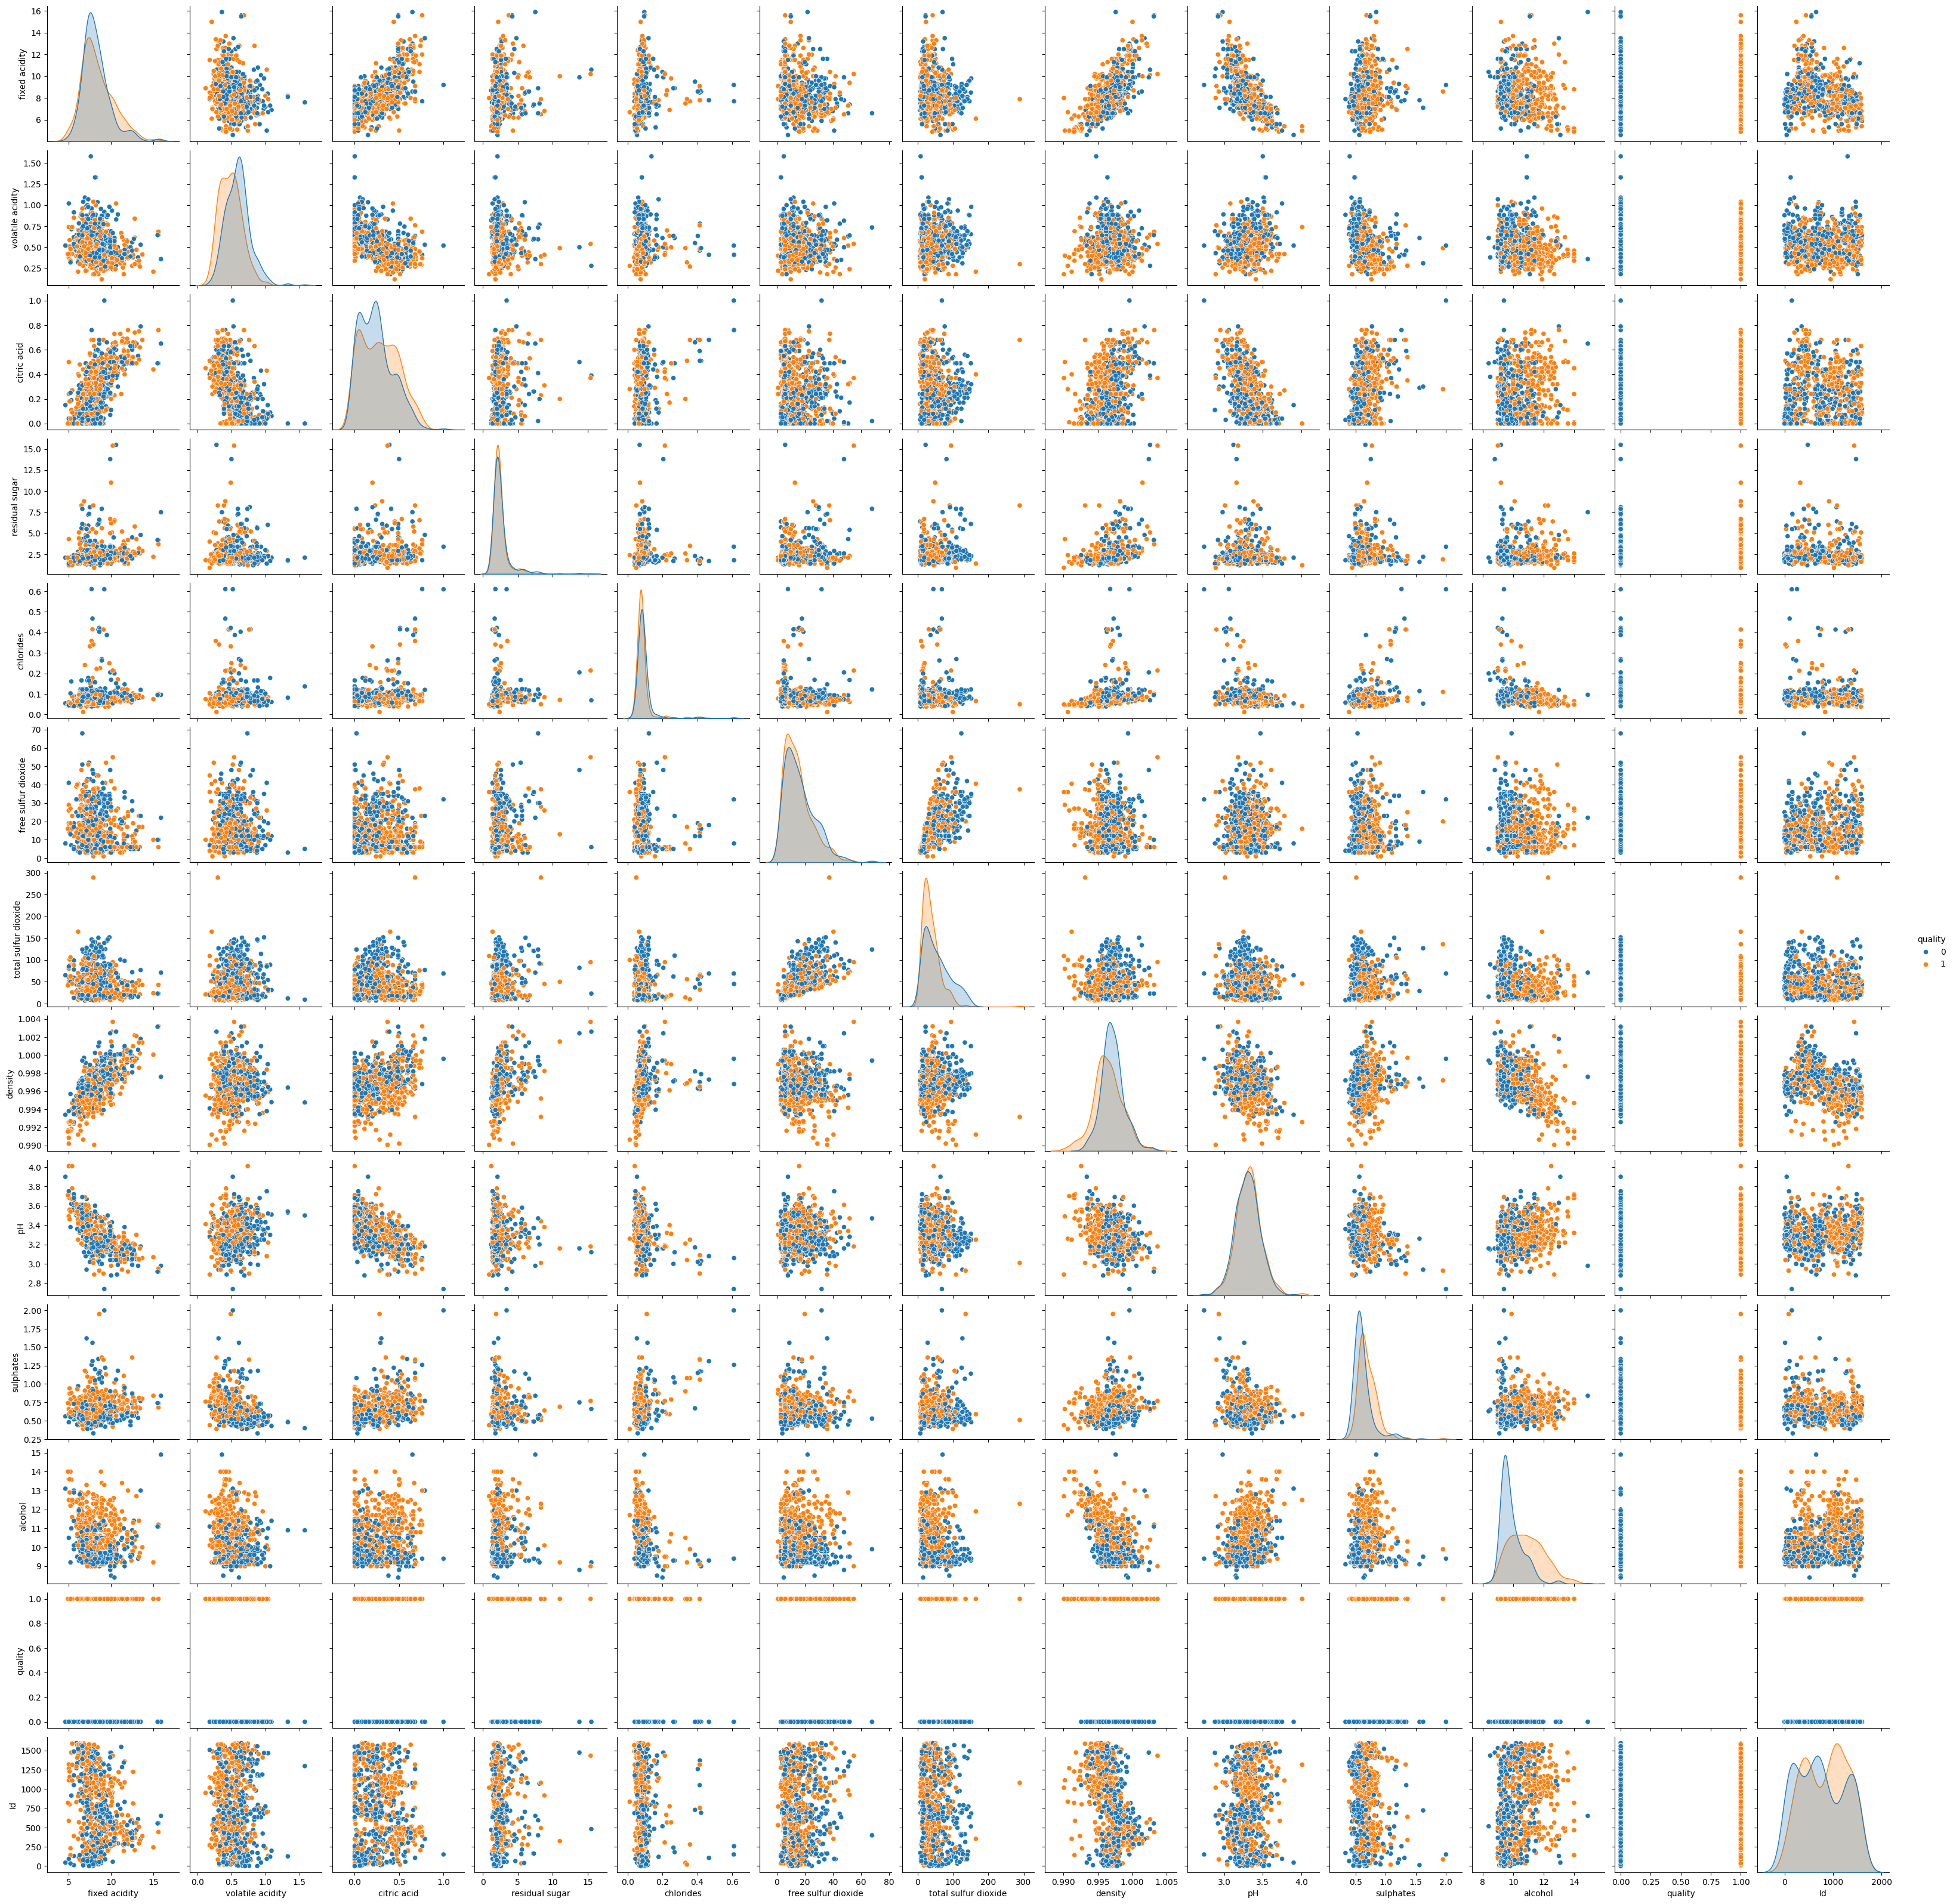

In [51]:

sns.pairplot(train, vars=train.keys(), hue="quality")

plt.show()

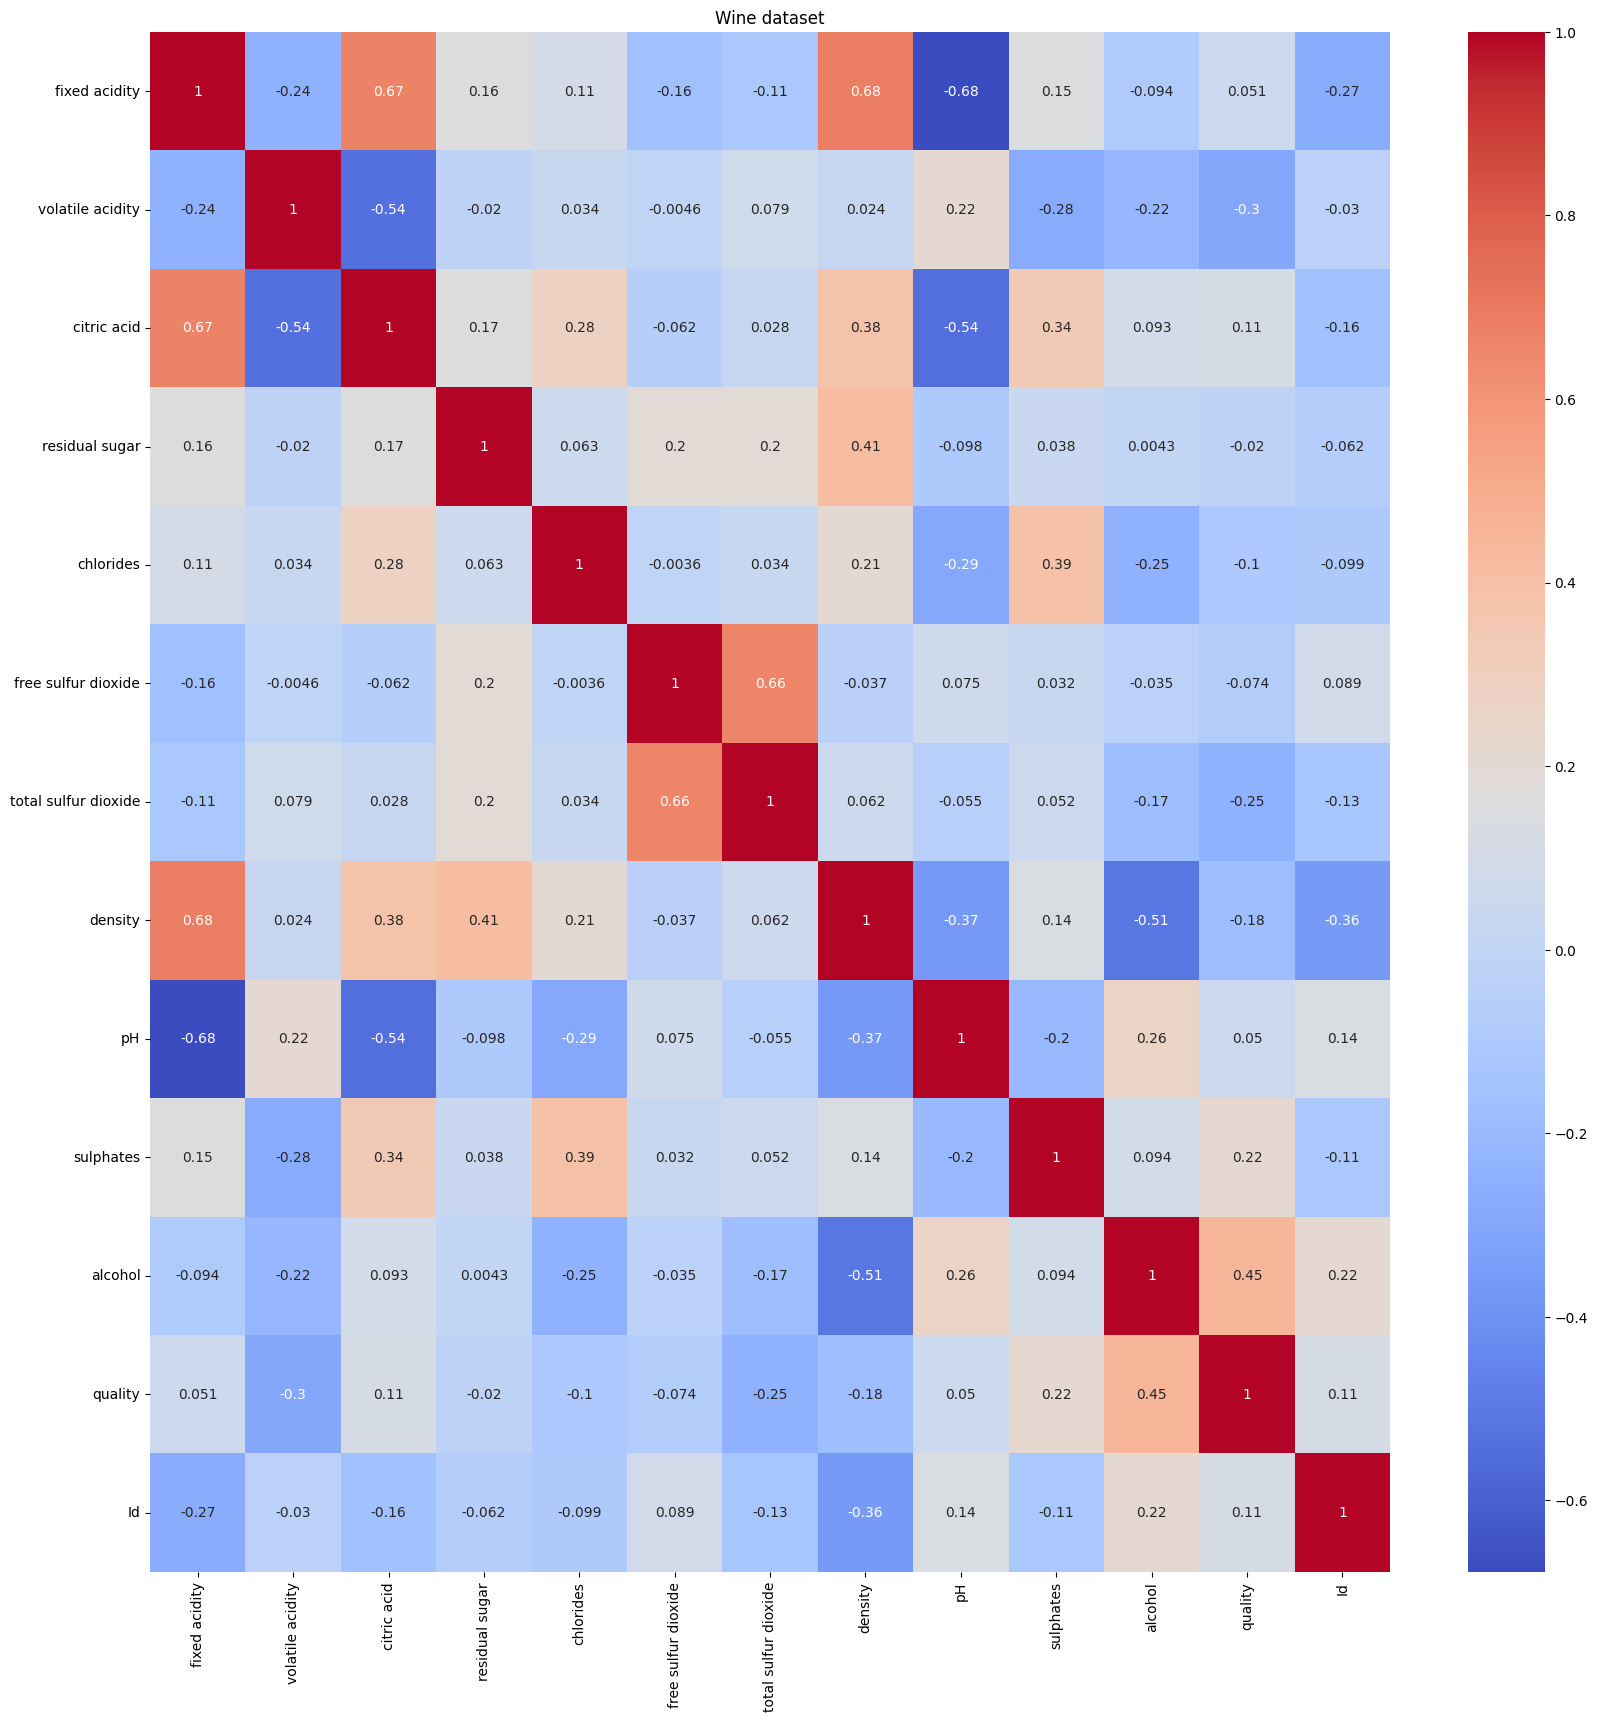

In [52]:
# Modified correlation heatmap taken from the 04_correlationmap.ipynb example from canvas
# https://nmbu.instructure.com/courses/14056/files/folder/Lecture_12_Preprocessing?preview=2814845
def plot_correlation_heatmap(data, title):
    """
    Plot a correlation heatmap for a given dataset
    """
    df = pd.DataFrame(data, columns=data.keys())
    df['quality'] = data.quality
    sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
    plt.title(title)
    plt.show()

plt.figure(figsize=(20, 20))
plot_correlation_heatmap(train, 'Wine dataset')

Based on the pairplot and the correlation heatmap, we conclude that no features are reduntant, and thus we use all features when training models

#### Boxplots
One boxplot per column, the box plot covers the middle 50% of values, the circles outside the ending lines are potential outliers, and the orange line is the median value.

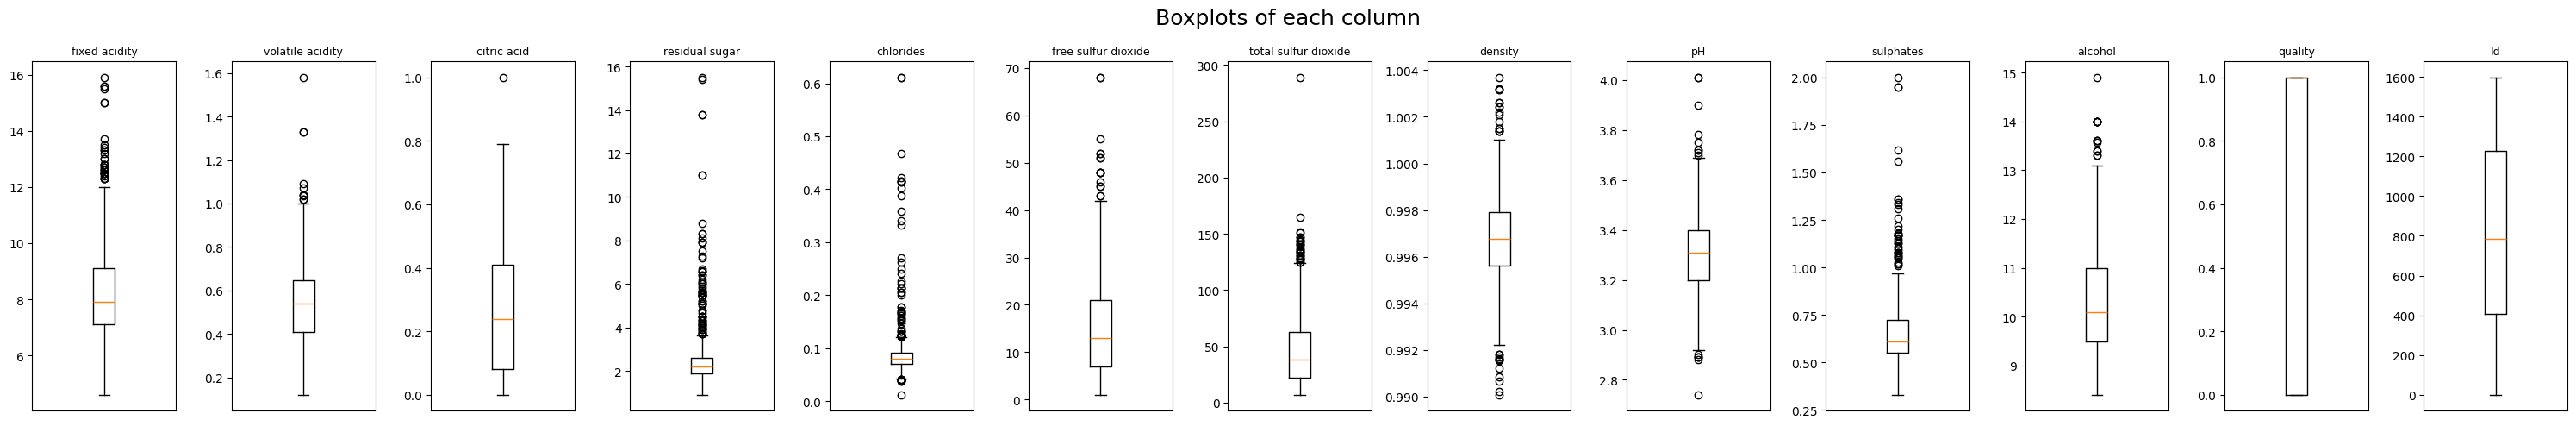

In [53]:
fig, ax = plt.subplots(1, len(train.columns), figsize=(30, 5))
fig.suptitle("Boxplots of each column", fontsize=18)

for i, col in enumerate(train.columns):
    ax[i].boxplot(train[col])
    ax[i].set_title(col, fontsize=9)
    ax[i].set_xticks([]) 

plt.tight_layout()
plt.show()

Based on the boxplot the data will benefit from scaling

### Data cleaning

In [54]:
print(train.shape)
print(test.shape)
train = train.dropna()
test = test.dropna()
print(train.shape)
print(test.shape)

print("No rows with missing data")


(835, 13)
(209, 12)
(835, 13)
(209, 12)
No rows with missing data


### Data preprocessing and visualisation

We decide not to train a perceptron model since it trains very slowly and performs poorly on datasets that are not linearly seperable. We also drop decisionTreeClassifier since randomForeest is multiple decisiontrees, so it is very unlikely that a single tree will perform better.

In [ ]:
train = train.sort_values("Id")
num_seeds = 5
X = train.drop(axis=1, labels=["quality", "Id"])
y = train["quality"]

scaler = StandardScaler()


classifier_types = [LogisticRegression, SVC, RandomForestClassifier, KNeighborsClassifier]
classifiers = []

for seed in range(num_seeds):
    for classifier in classifier_types:
        if classifier in (LogisticRegression, SVC):
            for c in range(-8,10,1):
                classifiers.append((classifier(max_iter=100, C = 10**c, random_state=seed), classifier))
        elif classifier == KNeighborsClassifier:
            for n_neighbors in range(1,13):
                classifiers.append((classifier(n_neighbors=n_neighbors), classifier))
        else:
            for depth in range(1,8):
                classifiers.append((classifier(n_estimators=1000, max_depth=depth, random_state=seed, criterion="gini"), classifier))


val_scores = np.zeros(num_seeds)
train_scores = np.zeros(num_seeds)

best_val_score = 0
corr_train_score = 0
best_model = None
for id, (classifier, classifier_type) in enumerate(classifiers):
    for seed in range(num_seeds):
        X_train, X_val, y_train, y_val = train_test_split(X, y, test_size = 0.3, random_state=seed)

        if classifier_type in [KNeighborsClassifier, RandomForestClassifier]:
            X_train_scaled = X_train
            X_val_scaled = X_val
        else:
            X_train_scaled = scaler.fit_transform(X_train)
            X_val_scaled = scaler.transform(X_val)


        classifier.fit(X_train, y_train)
        y_pred_train = classifier.predict(X_train)
        y_pred = classifier.predict(X_val)

        train_scores[seed] = accuracy_score(y_train, y_pred_train)
        val_scores[seed] = accuracy_score(y_val, y_pred)

    mean_val = val_scores.mean()
    mean_train = train_scores.mean()
    if mean_val > best_val_score:
        print(f"New Highscore: {mean_val}")
        best_val_score = mean_val
        corr_train_score = mean_train
        best_model = classifier
    print(f"Id: {id}")
print(f"Best model: {best_model} \n Validation Score: {best_val_score} \n Train score: {corr_train_score}")








New Highscore: 0.499601593625498
Id: 0
New Highscore: 0.5171314741035856
Id: 1
New Highscore: 0.5880478087649402
Id: 2
New Highscore: 0.5984063745019921
Id: 3
New Highscore: 0.6063745019920319
Id: 4
New Highscore: 0.6390438247011951
Id: 5
New Highscore: 0.6876494023904383
Id: 6
New Highscore: 0.7203187250996016
Id: 7
New Highscore: 0.7354581673306774
Id: 8
Id: 9
Id: 10
Id: 11
Id: 12
Id: 13
Id: 14
Id: 15
Id: 16
Id: 17
Id: 18
Id: 19
Id: 20
Id: 21
Id: 22
Id: 23
Id: 24
Id: 25
Id: 26
Id: 27
Id: 28
Id: 29
Id: 30
Id: 31
Id: 32
Id: 33
Id: 34
Id: 35
Id: 36
Id: 37
Id: 38
New Highscore: 0.7450199203187251
Id: 39
New Highscore: 0.749003984063745
Id: 40
New Highscore: 0.750597609561753
Id: 41
New Highscore: 0.756175298804781
Id: 42
Id: 43
Id: 44
Id: 45
Id: 46
Id: 47
Id: 48
Id: 49
Id: 50
Id: 51
Id: 52
Id: 53
Id: 54
Id: 55
Id: 56
Id: 57
Id: 58
Id: 59
Id: 60
Id: 61
Id: 62
Id: 63
Id: 64
Id: 65
Id: 66
Id: 67
Id: 68
Id: 69
Id: 70
Id: 71
Id: 72
Id: 73
Id: 74
Id: 75
Id: 76
Id: 77
Id: 78
Id: 79
Id: 80
Id: 8

### Modelling

In [80]:
test = pd.read_csv("test.csv")
test = test.sort_values("Id")
test_Ids = test["Id"]
test = test.drop(axis=1, labels=["Id"])

best_model.fit(X, y)

y_pred = best_model.predict(test)

submission = pd.DataFrame()
submission["ID"] = test_Ids
submission["quality"] = y_pred

### Final evaluation

### Kaggle submission

In [81]:
submission.to_csv("submission.csv",index=False)